In [12]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [13]:
graph_type = 'ER'
coup_type = 'ising'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")


beta_uni = 0.255413, beta_SG = 0.549306


In [14]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/perm/coal_time_DS_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique())
df

betas: [0.2  0.21 0.22] 
sizes: [ 100  500 1000 2500 5000]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.20,F_beta_Glauber,False,100,10,10000000,100,10,1778.0,785.168644
1,0.20,F_beta_Glauber,False,100,10,10000000,500,10,13434.0,6005.889043
2,0.20,F_beta_Glauber,False,100,10,10000000,1000,10,30889.9,7352.227995
3,0.20,F_beta_Glauber,False,100,10,10000000,2500,10,87332.4,14363.500021
4,0.20,F_beta_Glauber,False,100,10,10000000,5000,10,233810.8,50393.357050
5,0.21,F_beta_Glauber,False,100,10,10000000,100,10,1640.6,218.170667
6,0.21,F_beta_Glauber,False,100,10,10000000,500,10,15726.3,6498.638089
7,0.21,F_beta_Glauber,False,100,10,10000000,1000,10,33549.3,7950.523958
8,0.21,F_beta_Glauber,False,100,10,10000000,2500,10,121789.6,21941.614490
9,0.21,F_beta_Glauber,False,100,10,10000000,5000,10,283569.7,107933.238054


# Proba of coalescence

In [15]:
max_iter_plot = 10**7
N_plot = [100,500,1000,2500,5000]
mask = (
    (df['N'].isin(N_plot)) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.20,F_beta_Glauber,False,100,10,10000000,100,10,1778.0,785.168644
1,0.20,F_beta_Glauber,False,100,10,10000000,500,10,13434.0,6005.889043
2,0.20,F_beta_Glauber,False,100,10,10000000,1000,10,30889.9,7352.227995
3,0.20,F_beta_Glauber,False,100,10,10000000,2500,10,87332.4,14363.500021
4,0.20,F_beta_Glauber,False,100,10,10000000,5000,10,233810.8,50393.357050
5,0.21,F_beta_Glauber,False,100,10,10000000,100,10,1640.6,218.170667
6,0.21,F_beta_Glauber,False,100,10,10000000,500,10,15726.3,6498.638089
7,0.21,F_beta_Glauber,False,100,10,10000000,1000,10,33549.3,7950.523958
8,0.21,F_beta_Glauber,False,100,10,10000000,2500,10,121789.6,21941.614490
9,0.21,F_beta_Glauber,False,100,10,10000000,5000,10,283569.7,107933.238054


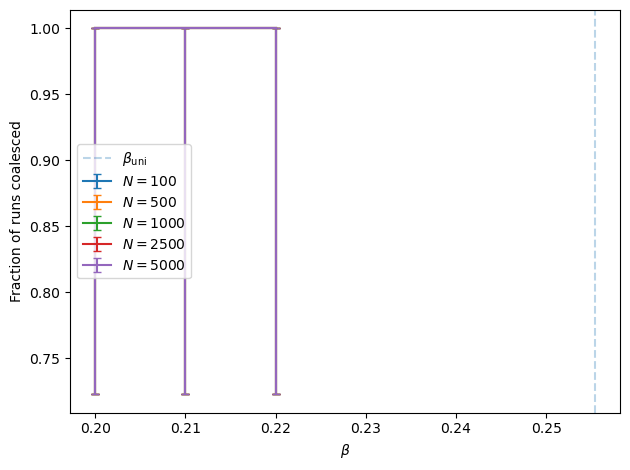

In [16]:
fig, ax = plt.subplots()

for N in df_filtered['N'].unique():
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    ax.errorbar(sub_df['beta'], p,
                yerr=[err_down, err_up],
                label=rf'$N={N}$', capsize=3)

ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
#fig.savefig(f'../results/perm/coal_DS_frac_{graph_type}_{coup_type}_d{d}.png', dpi=600, bbox_inches='tight')

# Scaling of coalescence times

In [10]:
max_iter_plot = 10**7
beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.20,F_beta_Glauber,False,100,10,10000000,100,10,1778.0,785.168644
1,0.20,F_beta_Glauber,False,100,10,10000000,500,10,13434.0,6005.889043
2,0.20,F_beta_Glauber,False,100,10,10000000,1000,10,30889.9,7352.227995
3,0.20,F_beta_Glauber,False,100,10,10000000,2500,10,87332.4,14363.500021
4,0.20,F_beta_Glauber,False,100,10,10000000,5000,10,233810.8,50393.357050
5,0.21,F_beta_Glauber,False,100,10,10000000,100,10,1640.6,218.170667
6,0.21,F_beta_Glauber,False,100,10,10000000,500,10,15726.3,6498.638089
7,0.21,F_beta_Glauber,False,100,10,10000000,1000,10,33549.3,7950.523958
8,0.21,F_beta_Glauber,False,100,10,10000000,2500,10,121789.6,21941.614490
9,0.21,F_beta_Glauber,False,100,10,10000000,5000,10,283569.7,107933.238054


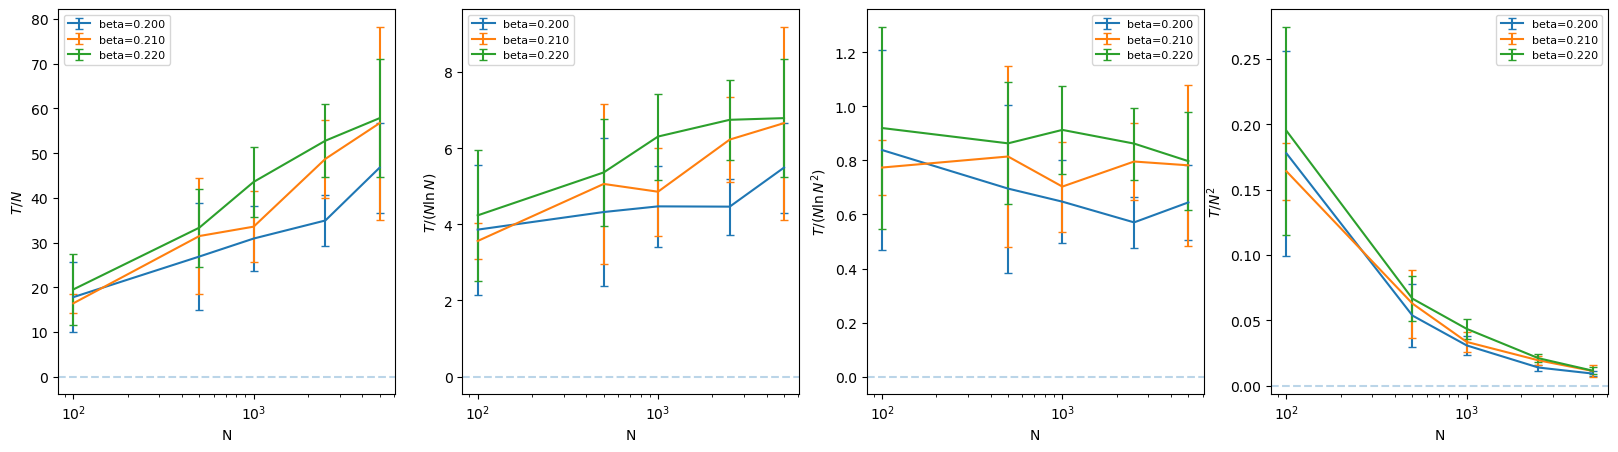

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
    ax.legend(fontsize=8)
plt.show()